In [2]:
import importlib.util
import numpy as np
import matplotlib.pyplot as plt
# Load local code.py directly by path
spec = importlib.util.spec_from_file_location("local_code", "code.py")
local_code = importlib.util.module_from_spec(spec)
spec.loader.exec_module(local_code)
PolarCode = local_code.PolarCode

Equation 4 from reference

$$Z(W) = \sum_{y \in Y} \sqrt{W(y\vert{}0)W(y\vert{}1)}$$

Choosing a Binary Symmetric Channel (BSC) with a bit flip probability ($p$), the transition probabilities are:
* $W(0\vert{}0) = 1 - p$
* $W(1\vert{}0) = p$
* $W(0\vert{}1) = p$
* $W(1\vert{}1) = 1 - p$

Substituting these into Equation 4 yields:
$$\begin{aligned} Z(W) &= \sqrt{W(0\vert{}0)W(0\vert{}1)} + \sqrt{W(1\vert{}0)W(1\vert{}1)} \\ Z(W) &= \sqrt{(1 - p) \cdot p} + \sqrt{p \cdot (1 - p)} \\ Z(W) &= 2 \sqrt{p(1 - p)} \end{aligned}$$

This is implemented in the code snippet:

```python
z0 = 2.0 * np.sqrt(p_flip * (1.0 - p_flip))

The Bhattacharyya parameters for the degraded (upper branch) and upgraded (lower branch) subchannels are recursively calculated using the following bounds:
\begin{align}
Z(W^-) &= 2Z - Z^2 \\
Z(W^+) &= Z^2
\end{align}
where $Z$ is the parameter of the parent channel


Instead, a variation function, $y(z)$, is used representing the change in the parameter after one polarization step:
\begin{equation}
y(z) = z - z^2
\end{equation}

By defining $y(Z) = Z - Z^2$ for a given parent channel parameter $Z$, we can rewrite the standard recursive formulas purely in terms of addition (additive channel) and subtraction (subtractive channel):
\begin{align}
Z_+ &= Z + y(Z) = Z + (Z - Z^2) = 2Z - Z^2 \\
Z_- &= Z - y(Z) = Z - (Z - Z^2) = Z^2
\end{align}

This reduces the number of calculations from 
\begin{align}
2(N - 1) to (N - 1)
\end{align}

Physical Channel Bit-Flip Probability (p): 0.0
2
4
8
16
32
64
128
256
512
1024
Physical Channel Bit-Flip Probability (p): 0.1
2
4
8
16
32
64
128
256
512
1024
Physical Channel Bit-Flip Probability (p): 0.2
2
4
8
16
32
64
128
256
512
1024
Physical Channel Bit-Flip Probability (p): 0.3
2
4
8
16
32
64
128
256
512
1024
Physical Channel Bit-Flip Probability (p): 0.4
2
4
8
16
32
64
128
256
512
1024
Physical Channel Bit-Flip Probability (p): 0.5
2
4
8
16
32
64
128
256
512
1024
Physical Channel Bit-Flip Probability (p): 0.6
2
4
8
16
32
64
128
256
512
1024
Physical Channel Bit-Flip Probability (p): 0.7
2
4
8
16
32
64
128
256
512
1024
Physical Channel Bit-Flip Probability (p): 0.8
2
4
8
16
32
64
128
256
512
1024
Physical Channel Bit-Flip Probability (p): 0.9
2
4
8
16
32
64
128
256
512
1024
Physical Channel Bit-Flip Probability (p): 1.0
2
4
8
16
32
64
128
256
512
1024


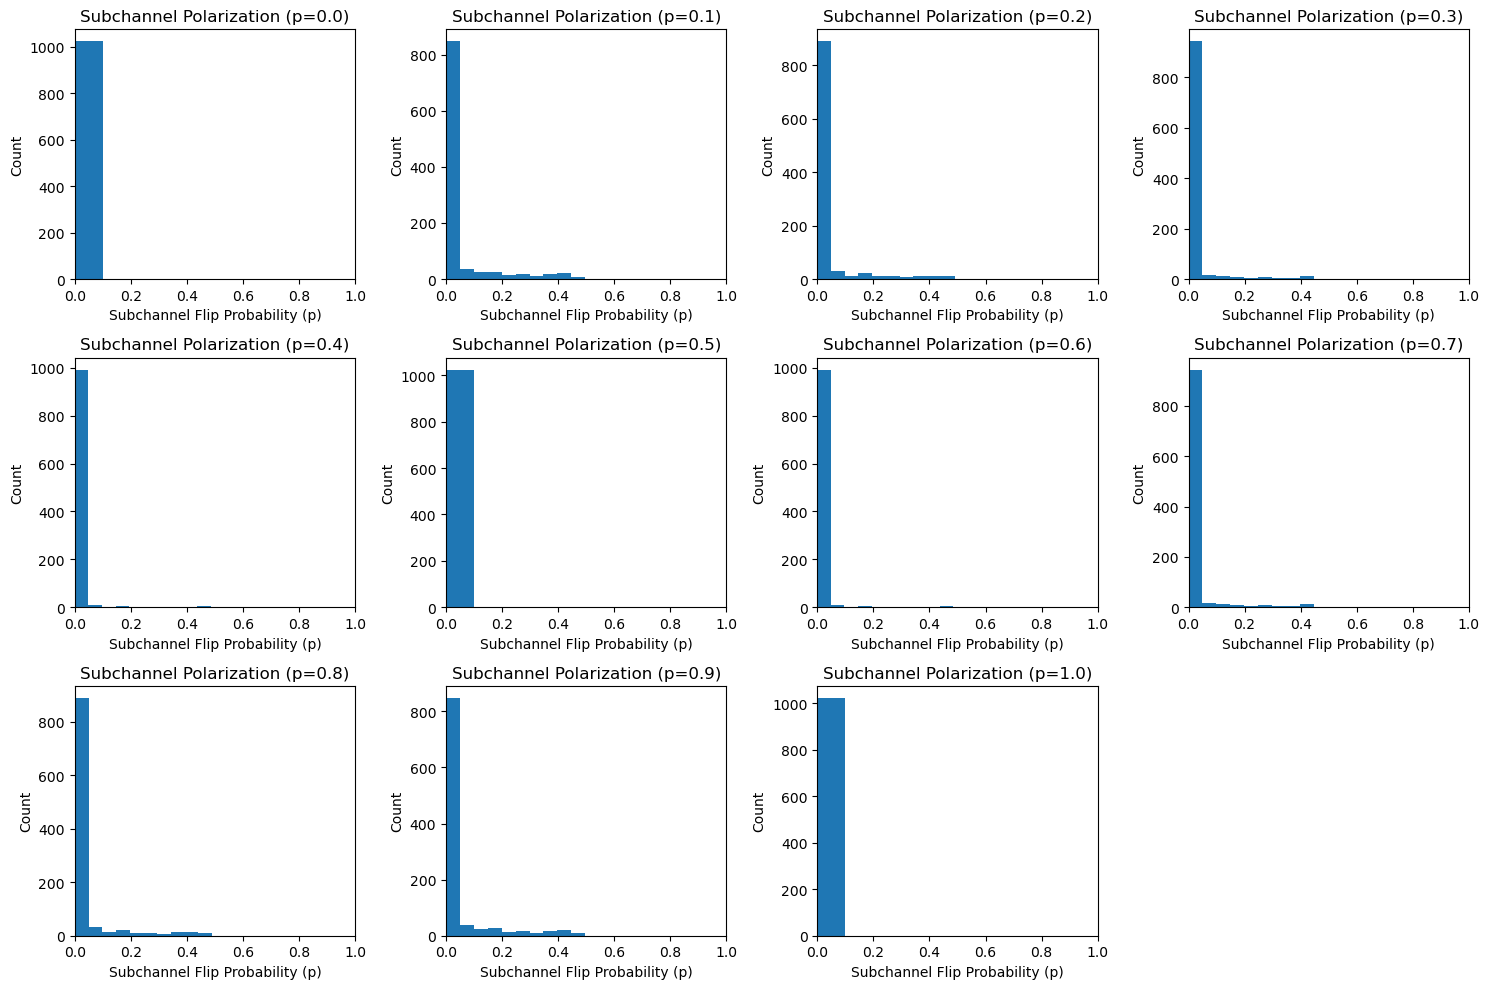

In [ ]:
# N = 32 # code length
# K = 12 # information bits

N = 1024
K = 500

fig, ax = plt.subplots(3, 4, figsize=(15, 10))
axes = ax.flatten() 

for idx, p_flip in enumerate(np.arange(0.0, 1.1, 0.1)):
    print(f"Physical Channel Bit-Flip Probability (p): {p_flip:.1f}")

    # Calculate Bhattacharyya reliability parameter for subchannel
    z0 = 2.0 * np.sqrt(p_flip * (1.0 - p_flip)) # channel specific calculation
    z = np.array([z0])
    while len(z) < N: # apply this for every channel
        new_z = np.empty(2 * len(z))
        y = z - z**2
        new_z[0::2] = np.clip(z + y, 0, 1) # upgraded channel
        new_z[1::2] = z - y # degraded channel
        z = new_z 

    # Subchannel bit-flip error probability upper bound: Pe <= 0.5 * Z
    channel_flip_probs = 0.5 * z
    # print("\n--- Subchannel Flip Probabilities ---")
    # for i, prob in enumerate(channel_flip_probs):
    #     print(f"  Channel {i}: {prob:.4f} flip probability")

    axes[idx].hist([val if val <= 0.5 else abs(1 - val) for val in z])
    # axes[idx].hist(z)
    
    axes[idx].set_xlabel("Subchannel Flip Probability (p)")
    axes[idx].set_ylabel("Count")
    axes[idx].set_xlim((0, 1))
    axes[idx].set_title(f"Subchannel Polarization (p={p_flip:.1f})")

fig.delaxes(axes[11])

plt.tight_layout()
plt.show()

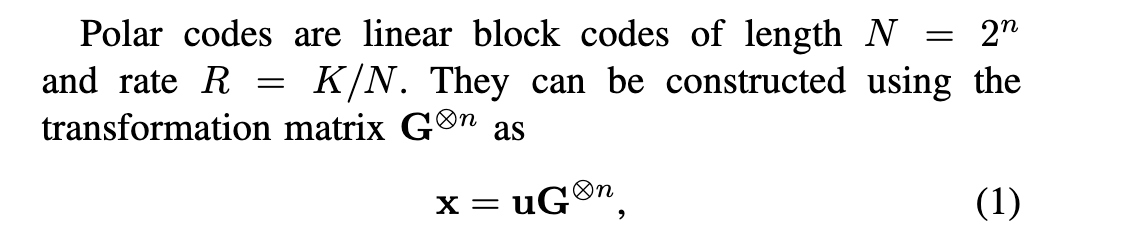

In [4]:
# polarized; choose close to 0; how choose channel prob so representative of channel rather than rng; 
# Rank channels: lowest flip probability = good channels, highest = bad channels
ranked_channels = np.argsort(channel_flip_probs)
info_indices = np.sort(ranked_channels[:K])     # Good channels (carry data)
frozen_indices = np.sort(ranked_channels[K:])   # Bad channels (frozen to 0)

print(f"\nGood channels (info):   {info_indices.tolist()}")
print(f"Bad channels (frozen):  {frozen_indices.tolist()}")

# Initialize PolarCode with the dynamically computed frozen indices
polar = PolarCode(N, K, frozen_indices)

# --- 2. Generate Random Information Bits & Encode ---
info_bits = np.array([1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1])
print(f"\nOriginal Info Bits: {info_bits}")

u, x = polar.encode(info_bits)
print(f"Full Input Vector u:    {u}")
print(f"Transmitted Codeword x: {x}")

# --- 3. Add Bit-Flip Noise (Binary Symmetric Channel) ---
# Each transmitted bit flips with probability p_flip
flip_noise = (np.random.rand(N) < p_flip).astype(int)
received_bits = (x + flip_noise) % 2


Good channels (info):   [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229

ValueError: shape mismatch: value array of shape (12,) could not be broadcast to indexing result of shape (500,)

# Successive Cancellation Decoding

In [ ]:
from SCdecoder import recursive_sc # smaller test case - not linked to earlier code

channel_llrs = [2, -3, 4, -2]
frozen_bits = {0, 1} 

decoded_msg = recursive_sc(channel_llrs, frozen_bits)
print(f"Decoded Message: {decoded_msg}") 

Decoded Message: [0, 0, 1, 1]


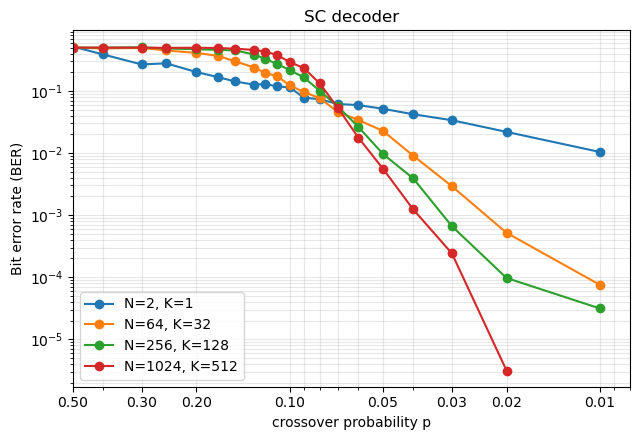

In [ ]:
local_code.plot_ber_rate_half(num_frames=5000, seed=1)
plt.show()

In [ ]:
print(f"Bit Flip Noise Vector:  {flip_noise}  ({np.sum(flip_noise)} bit(s) flipped)")
print(f"Received Bits (y):      {received_bits}")

# Convert received bits to Log-Likelihood Ratios (LLR) for BSC:
# LLR = ln( P(x=0|y) / P(x=1|y) )
# For y=0: +ln((1-p)/p), for y=1: -ln((1-p)/p)
llr_magnitude = np.log((1.0 - p_flip) / p_flip)
llr_input = (1 - 2 * received_bits) * llr_magnitude


# --- 4. Decode with Successive Cancellation ---
decoded_u = polar.decode_sc(llr_input)
extracted_info = decoded_u[polar.info_indices]
print(f"\nDecoded Info Bits:     {extracted_info}")

# --- 5. Verify Success ---
success = np.array_equal(info_bits, extracted_info)
print(f"Decoding Successful?   {success}")

Bit Flip Noise Vector:  [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]  (32 bit(s) flipped)
Received Bits (y):      [1 1 1 0 0 0 0 0 1 1 0 1 1 0 1 1 0 1 1 0 0 0 0 0 1 1 0 1 1 0 1 1]

Decoded Info Bits:     [1 0 1 1 0 1 0 1 1 0 1 1]
Decoding Successful?   True


/var/folders/_v/z5vhwfws6vv1mww46qw5k8h80000gn/T/ipykernel_905/3656342224.py:7: RuntimeWarning: divide by zero encountered in log
  llr_magnitude = np.log((1.0 - p_flip) / p_flip)


In [ ]:
SC vs CRC vs SCL choose one decoding algo

SyntaxError: invalid syntax (3873598191.py, line 1)